# **Heart Disease Prediction Using Machine Learning**

* This project uses machine learning classification algorithms to predict
 the presence of heart disease based on patient health-related features.

* The workflow includes data exploration, preprocessing, model training,
 evaluation, and hyperparameter tuning.

## 1. Import Libraries

In [1]:
import pandas as pd 
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns 
%matplotlib inline
from sklearn.model_selection import train_test_split,GridSearchCV
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import (confusion_matrix,
                             classification_report,
                             precision_score,recall_score,
                             accuracy_score,f1_score,
                             roc_auc_score,
                             RocCurveDisplay)


## 2. Load Dataset

In [2]:
df = pd.read_csv('heart-disease-dataset.csv')

## 3. Initial Data Exploration

In [3]:
df.head()

,age,sex,chest_pain_type,resting_bp_s,cholesterol,fasting_blood_sugar,resting_ecg,max_heart_rate,exercise_angina,oldpeak,st_slope,target
0,40.0,1.0,2.0,140.0,289.0,0.0,0.0,172.0,0.0,0.0,1.0,0.0
1,49.0,0.0,3.0,160.0,180.0,0.0,0.0,156.0,0.0,1.0,2.0,1.0
2,37.0,1.0,2.0,130.0,283.0,0.0,1.0,98.0,0.0,0.0,1.0,0.0
3,48.0,0.0,4.0,138.0,214.0,0.0,0.0,108.0,1.0,1.5,2.0,1.0
4,54.0,1.0,3.0,150.0,195.0,0.0,0.0,122.0,0.0,0.0,1.0,0.0


In [4]:
df.tail()

,age,sex,chest_pain_type,resting_bp_s,cholesterol,fasting_blood_sugar,resting_ecg,max_heart_rate,exercise_angina,oldpeak,st_slope,target
1185,45.0,1.0,1.0,110.0,264.0,0.0,0.0,132.0,0.0,1.2,2.0,1.0
1186,68.0,1.0,4.0,144.0,193.0,1.0,0.0,141.0,0.0,3.4,2.0,1.0
1187,57.0,1.0,4.0,130.0,131.0,0.0,0.0,115.0,1.0,1.2,2.0,1.0
1188,57.0,0.0,2.0,130.0,236.0,0.0,2.0,174.0,0.0,0.0,2.0,1.0
1189,38.0,1.0,3.0,138.0,175.0,0.0,0.0,173.0,0.0,0.0,1.0,0.0


In [5]:
df.shape

(1190, 12)

In [6]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 1190 entries, 0 to 1189
Data columns (total 12 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   age                  1190 non-null   float64
 1   sex                  1190 non-null   float64
 2   chest_pain_type      1190 non-null   float64
 3   resting_bp_s         1190 non-null   float64
 4   cholesterol          1190 non-null   float64
 5   fasting_blood_sugar  1190 non-null   float64
 6   resting_ecg          1190 non-null   float64
 7   max_heart_rate       1190 non-null   float64
 8   exercise_angina      1190 non-null   float64
 9   oldpeak              1190 non-null   float64
 10  st_slope             1190 non-null   float64
 11  target               1190 non-null   float64
dtypes: float64(12)
memory usage: 111.7 KB


In [7]:
# convert target column to integer
df['target']=df['target'].astype(int)

### Statistical Summary

The following table provides descriptive statistics for the numerical features.

In [8]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
age,1190.0,53.720168,9.358203,28.0,47.0,54.0,60.00,77.0
sex,1190.0,0.763866,0.424884,0.0,1.0,1.0,1.00,1.0
chest_pain_type,1190.0,3.232773,0.935480,1.0,3.0,4.0,4.00,4.0
resting_bp_s,1190.0,132.153782,18.368823,0.0,120.0,130.0,140.00,200.0
cholesterol,1190.0,210.363866,101.420489,0.0,188.0,229.0,269.75,603.0
fasting_blood_sugar,1190.0,0.213445,0.409912,0.0,0.0,0.0,0.00,1.0
resting_ecg,1190.0,0.698319,0.870359,0.0,0.0,0.0,2.00,2.0
max_heart_rate,1190.0,139.732773,25.517636,60.0,121.0,140.5,160.00,202.0
exercise_angina,1190.0,0.387395,0.487360,0.0,0.0,0.0,1.00,1.0
oldpeak,1190.0,0.922773,1.086337,-2.6,0.0,0.6,1.60,6.2


## 4. Data Cleaning

In [9]:
df.isna().sum()

age                    0
sex                    0
chest_pain_type        0
resting_bp_s           0
cholesterol            0
fasting_blood_sugar    0
resting_ecg            0
max_heart_rate         0
exercise_angina        0
oldpeak                0
st_slope               0
target                 0
dtype: int64

> * No missing values were found in the dataset, so no imputation was required.

In [10]:
duplicate_count = df.duplicated().sum()

print(f"Duplicate rows: {duplicate_count}")

df = df.drop_duplicates().reset_index(drop=True)

Duplicate rows: 272


> * 272 duplicate rows were identified and removed.

##  5. Exploratory Data Analysis

In [11]:
df.target.value_counts()

target
1    508
0    410
Name: count, dtype: int64

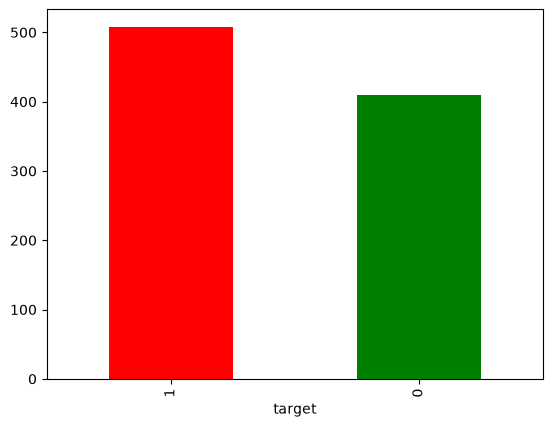

In [12]:
df.target.value_counts().plot(kind="bar",color=["red","green"]);

In [13]:
df.sex.value_counts()

sex
1.0    725
0.0    193
Name: count, dtype: int64

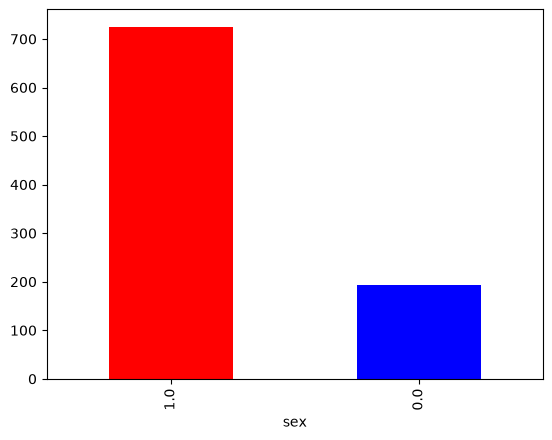

In [14]:
df.sex.value_counts().plot(kind="bar",color=["red","blue"]);

In [15]:
df.fasting_blood_sugar.value_counts()

fasting_blood_sugar
0.0    704
1.0    214
Name: count, dtype: int64

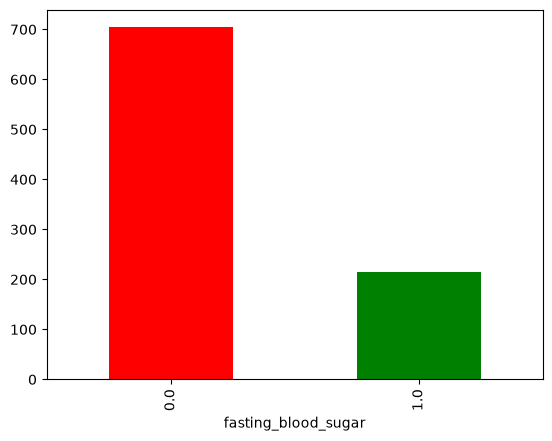

In [16]:
df.fasting_blood_sugar.value_counts().plot(kind="bar",color=["red","green"]);

In [17]:
pd.crosstab(df.target,df.sex)

sex,0.0,1.0
target,,
0,143,267
1,50,458


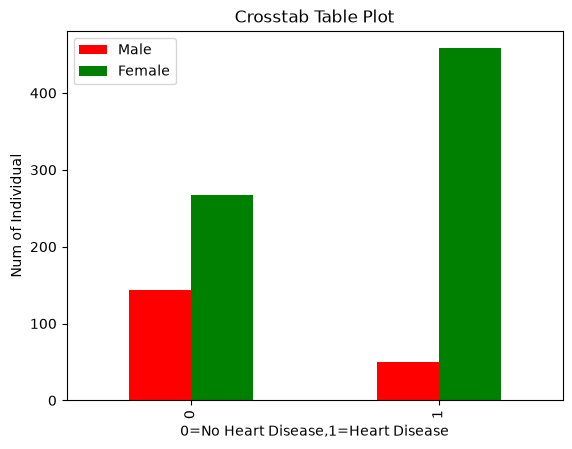

In [18]:
pd.crosstab(df.target,df.sex).plot(kind="bar",
                                   color=['red','green'])
plt.title("Crosstab Table Plot")
plt.xlabel("0=No Heart Disease,1=Heart Disease")
plt.ylabel("Num of Individual")
plt.legend(["Male","Female"]);

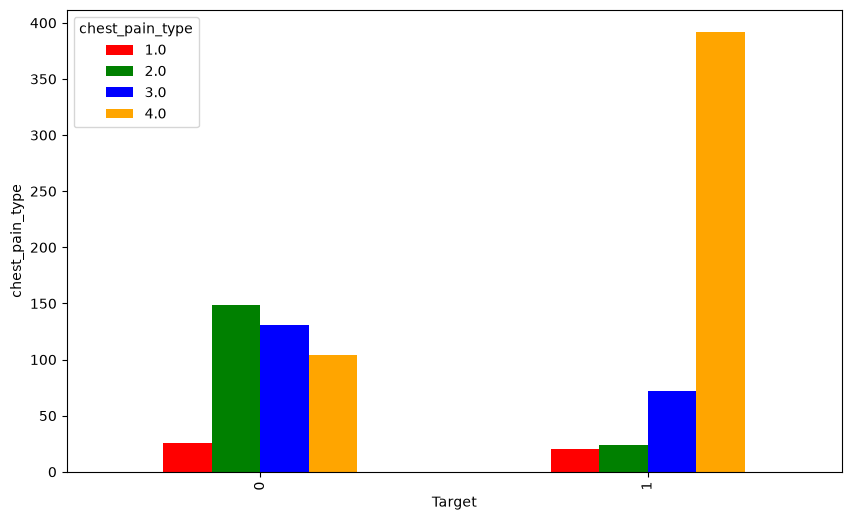

In [19]:
pd.crosstab(df.target,df.chest_pain_type).plot(kind='bar',
                                               color=["red","green","blue","orange"],
                                               figsize=(10,6))

plt.xlabel("Target")
plt.ylabel("chest_pain_type");

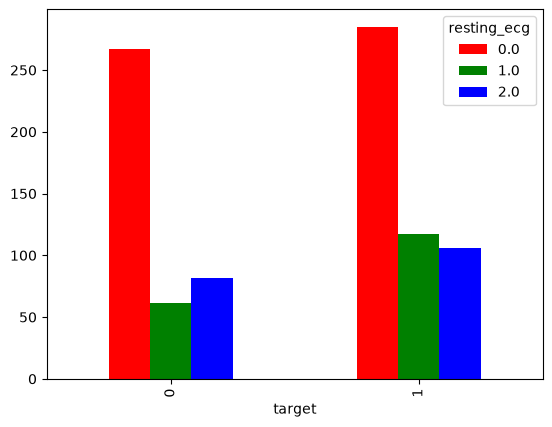

In [20]:
pd.crosstab(df.target,df.resting_ecg).plot(kind="bar",
                                           color=["red","green","blue"]);

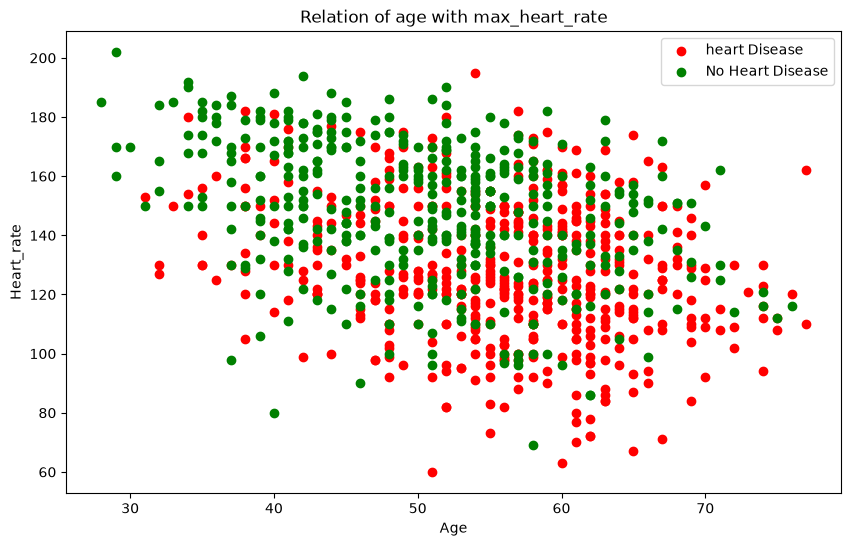

In [21]:
plt.figure(figsize=(10,6))
plt.scatter(df.age[df.target==1],df.max_heart_rate[df.target==1],c='red')
plt.scatter(df.age[df.target==0],df.max_heart_rate[df.target==0],c='green')
plt.title("Relation of age with max_heart_rate")
plt.xlabel("Age")
plt.ylabel("Heart_rate")
plt.legend(["heart Disease","No Heart Disease"]);

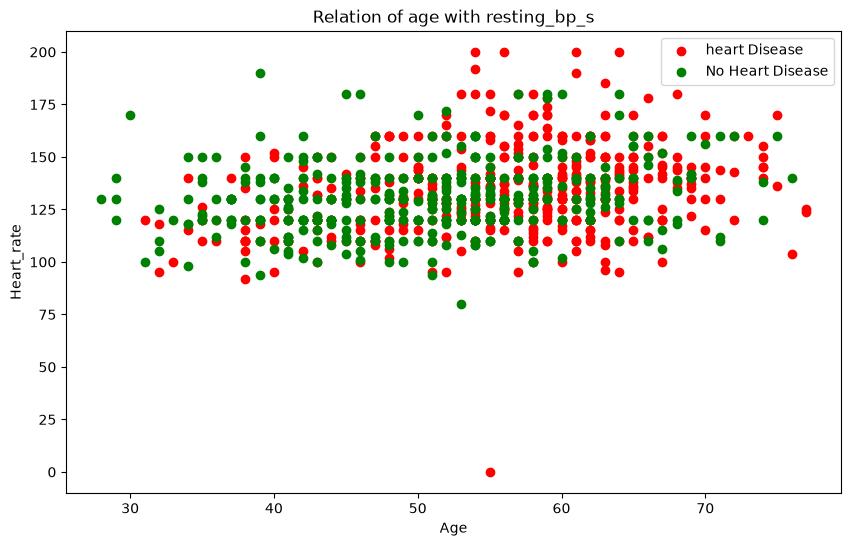

In [22]:
plt.figure(figsize=(10,6))
plt.scatter(df.age[df.target==1],df.resting_bp_s[df.target==1],c='red')
plt.scatter(df.age[df.target==0],df.resting_bp_s[df.target==0],c='green')
plt.title("Relation of age with resting_bp_s")
plt.xlabel("Age")
plt.ylabel("Heart_rate")
plt.legend(["heart Disease","No Heart Disease"]);

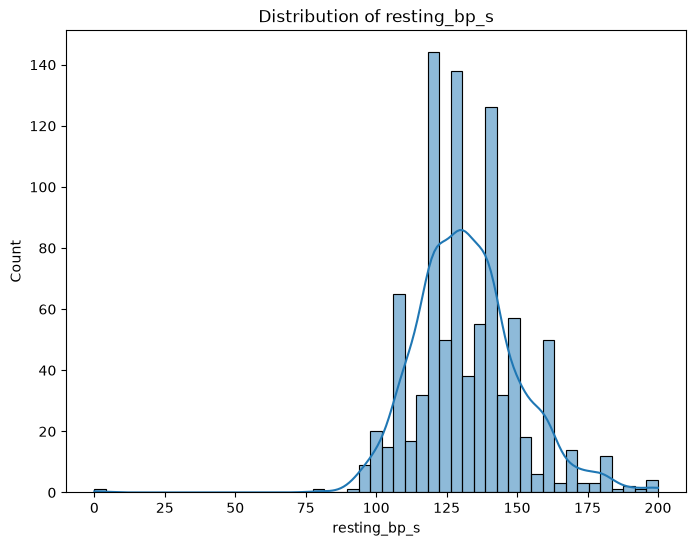

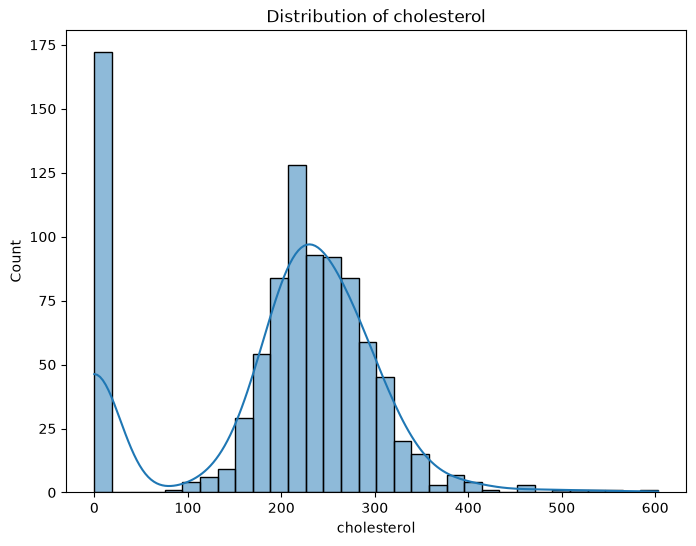

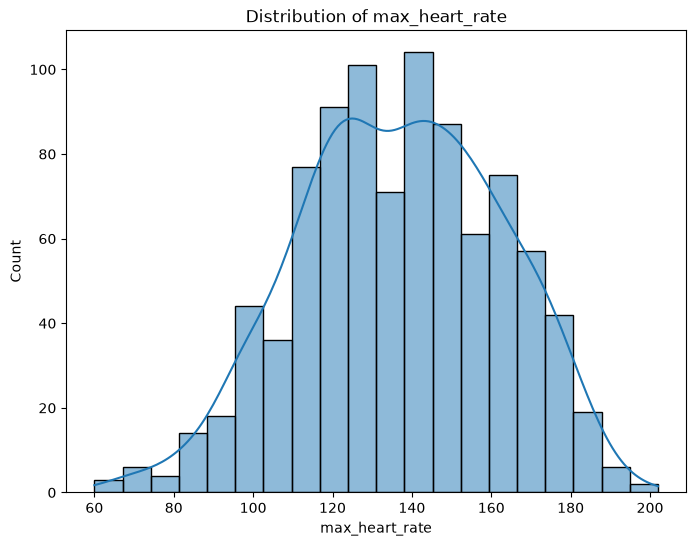

In [23]:
num_col=['resting_bp_s','cholesterol','max_heart_rate']

for col in num_col:
    plt.figure(figsize=(8,6))
    sns.histplot(df[col],kde=True)
    plt.title(f"Distribution of {col}")
    plt.show();

<Axes: >

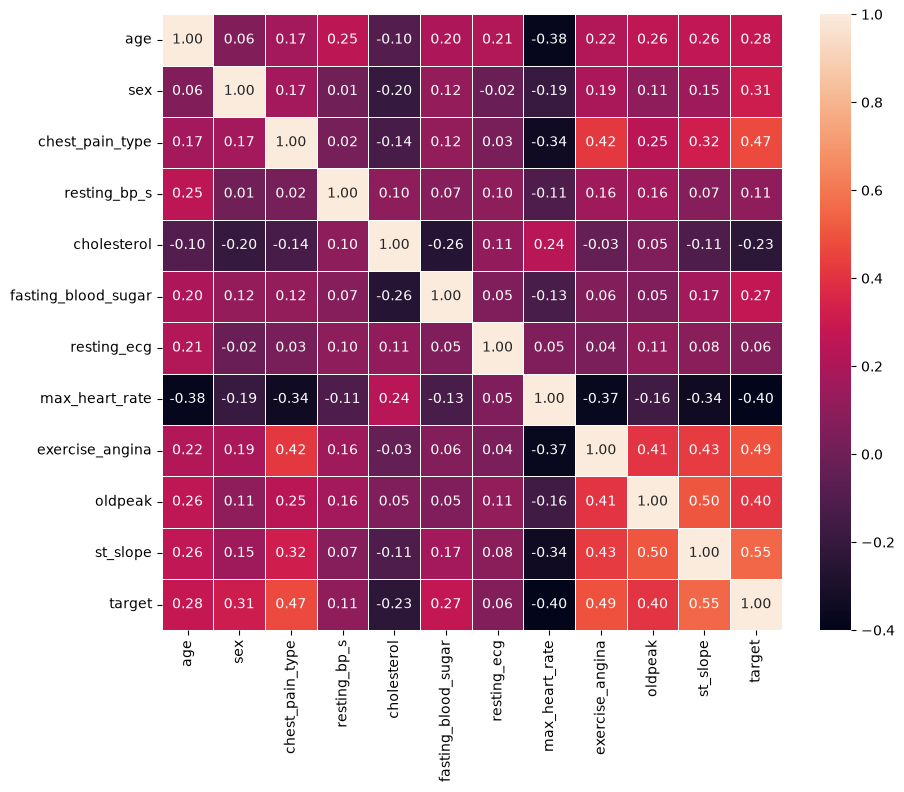

In [24]:
plt.figure(figsize=(10,8))
sns.heatmap(df.corr(),fmt="0.2f",annot=True,cbar="YlGnBu",linewidths=0.5)

## 6. Train-Test Split

In [25]:
X=df.drop("target",axis=1)
y=df["target"]

X_train,X_test,y_train,y_test=train_test_split(X,y,test_size=0.2,random_state=42)

In [26]:
## Creates instance of model
Lr_model=LogisticRegression(
    C=1.0,
    solver="liblinear")
Dtc_model=DecisionTreeClassifier(
    criterion="gini",
    max_depth=None,
    min_samples_split=2,
    min_samples_leaf=1,
    max_features=None,
    random_state=42)
Rfc_model=RandomForestClassifier(
    n_estimators=400,
    min_samples_leaf=7,
    min_samples_split=14,
    n_jobs=-1,
    random_state=42)

## 7. Model Training

>  **LogisticRegression Model**

In [27]:
Lr_model.fit(X_train,y_train)

,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use in the optimization problem. Default is 'lbfgs'.To choose a solver, you might want to consider the following aspects:- 'lbfgs' is a good default solver because it works reasonably well for a wide class of problems.- For :term:`multiclass` problems (`n_classes >= 3`), all solvers except 'liblinear' minimize the full multinomial loss, 'liblinear' will raise an error.- 'newton-cholesky' is a good choice for `n_samples` >> `n_features * n_classes`, especially with one-hot encoded categorical features with rare categories. Be aware that the memory usage of this solver has a quadratic dependency on `n_features * n_classes` because it explicitly computes the full Hessian matrix.- For small datasets, 'liblinear' is a good choice, whereas 'sag' and 'saga' are faster for large ones;- 'liblinear' can only handle binary classification by default. To apply a one-versus-rest scheme for the multiclass setting one can wrap it with the :class:`~sklearn.multiclass.OneVsRestClassifier`... warning:: The choice of the algorithm depends on the penalty chosen (`l1_ratio=0` for L2-penalty, `l1_ratio=1` for L1-penalty and `0 < l1_ratio < 1` for Elastic-Net) and on (multinomial) multiclass support: ================= ======================== ====================== solver l1_ratio multinomial multiclass ================= ======================== ====================== 'lbfgs' l1_ratio=0 yes 'liblinear' l1_ratio=1 or l1_ratio=0 no 'newton-cg' l1_ratio=0 yes 'newton-cholesky' l1_ratio=0 yes 'sag' l1_ratio=0 yes 'saga' 0<=l1_ratio<=1 yes ================= ======================== ======================.. note:: 'sag' and 'saga' fast convergence is only guaranteed on features with approximately the same scale. You can preprocess the data with a scaler from :mod:`sklearn.preprocessing`... seealso:: Refer to the :ref:`User Guide <Logistic_regression>` for more information regarding :class:`LogisticRegression` and more specifically the :ref:`Table <logistic_regression_solvers>` summarizing solver/penalty supports... versionadded:: 0.17 Stochastic Average Gradient (SAG) descent solver. Multinomial support in version 0.18... versionadded:: 0.19 SAGA solver... versionchanged:: 0.22 The default solver changed from 'liblinear' to 'lbfgs' in 0.22... versionadded:: 1.2 newton-cholesky solver. Multinomial support in version 1.6.",'liblinear'
,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add an L2 penalty term and it is the default choice;- `'l1'`: add an L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` and `C` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'`, `l1_ratio` set to any float between 0 and 1 for `penalty='elasticnet'`, and `C=np.inf` for `penalty=None`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some pen

In [28]:
print("Test_score: ",Lr_model.score(X_test,y_test))

Test_score:  0.8315217391304348


In [29]:
Lr_predy=Lr_model.predict(X_test)
print("accuracy_score:",accuracy_score(y_test,Lr_predy))
print("precision_score:",precision_score(y_test,Lr_predy))
print("Recall_score:",recall_score(y_test,Lr_predy))
print("f1_score:",f1_score(y_test,Lr_predy))
print("\nConfusion_matrix:\n",confusion_matrix(y_test,Lr_predy))

accuracy_score: 0.8315217391304348
precision_score: 0.8958333333333334
Recall_score: 0.8037383177570093
f1_score: 0.8472906403940886

Confusion_matrix:
 [[67 10]
 [21 86]]


>  **DecisionTreeClassifier**

In [30]:
Dtc_model.fit(X_train,y_train)

,"random_state random_state: int, RandomState instance or None, default=NoneControls the randomness of the estimator. The features are alwaysrandomly permuted at each split, even if ``splitter`` is set to``""best""``. When ``max_features < n_features``, the algorithm willselect ``max_features`` at random at each split before finding the bestsplit among them. But the best found split may vary across differentruns, even if ``max_features=n_features``. That is the case, if theimprovement of the criterion is identical for several splits and onesplit has to be selected at random. To obtain a deterministic behaviourduring fitting, ``random_state`` has to be fixed to an integer.See :term:`Glossary <random_state>` for details.",42
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.",'gini'
,"splitter splitter: {""best"", ""random""}, default=""best""The strategy used to choose the split at each node. Supportedstrategies are ""best"" to choose the best split and ""random"" to choosethe best random split.",'best'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: int, float or {""sqrt"", ""log2""}, default=NoneThe number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`... note:: The search for a split does not stop until at least one valid partition of the node samples is found, even if it requires to effectively inspect more than ``max_features`` features.",None
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow a tree with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsamples 

In [31]:
Dtc_model.score(X_test,y_test)

0.8260869565217391

In [32]:
Dtc_predy=Dtc_model.predict(X_test)
print("accuracy_score:",accuracy_score(y_test,Dtc_predy))
print("precision_score:",precision_score(y_test,Dtc_predy))
print("Recall_score:",recall_score(y_test,Lr_predy))
print("f1_score:",f1_score(y_test,Dtc_predy))
print("\nConfusion_matrix:\n",confusion_matrix(y_test,Dtc_predy))

accuracy_score: 0.8260869565217391
precision_score: 0.8947368421052632
Recall_score: 0.8037383177570093
f1_score: 0.8415841584158416

Confusion_matrix:
 [[67 10]
 [22 85]]


> **RandomForestClassifier**

In [33]:
Rfc_model.fit(X_train,y_train)

,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",400
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",14
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",7
,"n_jobs n_jobs: int, default=NoneThe number of jobs to run in parallel. :meth:`fit`, :meth:`predict`,:meth:`decision_path` and :meth:`apply` are all parallelized over thetrees. ``None`` means 1 unless in a :obj:`joblib.parallel_backend`context. ``-1`` means using all processors. See :term:`Glossary<n_jobs>` for more details.",-1
,"random_state random_state: int, RandomState instance or None, default=NoneControls both the randomness of the bootstrapping of the samples usedwhen building trees (if ``bootstrap=True``) and the sampling of thefeatures to consider when looking for the best split at each node(if ``max_features < n_features``).See :term:`Glossary <random_state>` for details.",42
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.Note: This parameter is tree-specific.",'gini'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",None
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=""sqrt""The number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`... versionchanged:: 1.1 The default of `max_features` changed from `""auto""` to `""sqrt""`.Note: the search for a split does not stop until at least onevalid partition of the node samples is found, even if it requires toeffectively inspect more than ``max_features`` features.",'sqrt'
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow trees with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the tota

In [34]:
Rfc_model.score(X_test,y_test)

0.875

In [35]:
Rfc_predy=Rfc_model.predict(X_test)
print("accuracy_score:",accuracy_score(y_test,Rfc_predy))
print("precision_score:",precision_score(y_test,Rfc_predy))
print("Recall_score:",recall_score(y_test,Lr_predy))
print("f1_score:",f1_score(y_test,Rfc_predy))
print("\nConfusion_matrix:\n",confusion_matrix(y_test,Rfc_predy))

accuracy_score: 0.875
precision_score: 0.9038461538461539
Recall_score: 0.8037383177570093
f1_score: 0.8909952606635071

Confusion_matrix:
 [[67 10]
 [13 94]]


## **Model Comparision**

In [36]:
model_score={
    'LR':0.8315217391304348,
    'DTC':0.8260869565217391,
    "RFC":0.8913043478260869
}
model_score

{'LR': 0.8315217391304348,
 'DTC': 0.8260869565217391,
 'RFC': 0.8913043478260869}

(array([0]), [Text(0, 0, 'Accuracy')])

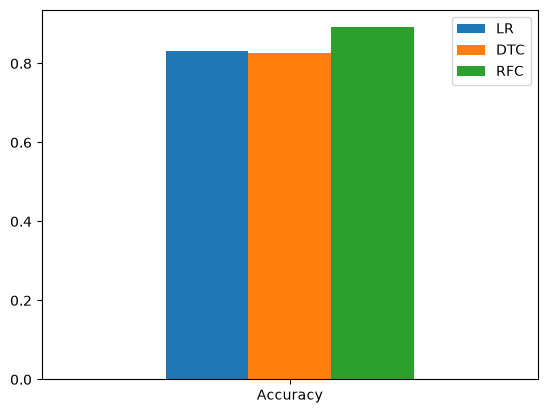

In [37]:
model_com=pd.DataFrame(model_score,index=["Accuracy"])
model_com.plot(kind="bar")
plt.xticks(rotation=False)

## 8. Hyperparameter Tuning with GridSearchCV

In [38]:
lr_params = {
    "C": np.logspace(-4, 4, 20),
    "solver": ["liblinear", "lbfgs"],
    "penalty": ["l2"]
}
dtc_params = {
    "criterion": ["gini", "entropy", "log_loss"],
    "max_depth": [3, 5, 7, 10, 15, 20, None],
    "min_samples_split": [2, 5, 10, 20],
    "min_samples_leaf": [1, 2, 4, 8],
    "max_features": [None, "sqrt", "log2"]
}
rfc_params = {
    "n_estimators": [100, 200, 300, 500],
    "max_depth": [None, 5, 10, 15, 20],
    "min_samples_split": [2, 5, 10],
    "min_samples_leaf": [1, 2, 4],
    "max_features": ["sqrt", "log2", None]
}

> **LR GridSearchCV**

In [39]:
Lgs_model = GridSearchCV(
    LogisticRegression(),
    lr_params,
    cv=5,
    scoring="accuracy",
    n_jobs=-1
)

In [40]:
Lgs_model.fit(X_train,y_train)

c:\Users\Muhammad waseem\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\sklearn\linear_model\_logistic.py:1403: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', l1_ratio set to a float between 0 and 1 instead of penalty='elasticnet', and C=np.inf instead of penalty=None.
  warnings.warn(


,"estimator estimator: estimator objectThis is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.",LogisticRegression()
,"param_grid param_grid: dict or list of dictionariesDictionary with parameters names (`str`) as keys and lists ofparameter settings to try as values, or a list of suchdictionaries, in which case the grids spanned by each dictionaryin the list are explored. This enables searching over any sequenceof parameter settings.","{'C': array([1.0000...00000000e+04]), 'penalty': ['l2'], 'solver': ['liblinear', 'lbfgs']}"
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.",'accuracy'
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",-1
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",5
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``GridSearchCV`` instance.Also for multiple metric evaluation, the attributes ``best_index_``,``best_score_`` and ``best_params_`` will only be available if``refit`` is set and all of them will be determined w.r.t this specificscorer.See ``scoring`` parameter to know more about multiple metricevaluation.See :ref:`sphx_glr_auto_examples_model_selection_plot_grid_search_digits.py`to see how to design a custom selection strategy using a callablevia `refit`.See :ref:`this example<sphx_glr_auto_examples_model_selection_plot_grid_search_refit_callable.py>`for an example of how to use ``refit=callable`` to balance modelcomplexity and cross-validated score... versionchanged:: 0.20 Support for callable added.",True
,"verbose verbose: int, default=0Controls the

In [41]:
Lgs_model.score(X_test,y_test)

0.842391304347826

In [42]:
Lgs_predy=Lgs_model.predict(X_test)
print("accuracy_score:",accuracy_score(y_test,Lgs_predy))
print("precision_score:",precision_score(y_test,Lgs_predy))
print("Recall_score:",recall_score(y_test,Lgs_predy))
print("f1_score:",f1_score(y_test,Lgs_predy))
print("\nConfusion_matrix:\n",confusion_matrix(y_test,Lgs_predy))

accuracy_score: 0.842391304347826
precision_score: 0.90625
Recall_score: 0.8130841121495327
f1_score: 0.8571428571428571

Confusion_matrix:
 [[68  9]
 [20 87]]


In [43]:
Dgs_model=GridSearchCV(
    DecisionTreeClassifier(),
    param_grid=dtc_params,
    cv=5,
    n_jobs=-1,
    verbose=2
)
Dgs_model.fit(X_train,y_train)

Fitting 5 folds for each of 1008 candidates, totalling 5040 fits


,"estimator estimator: estimator objectThis is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.",DecisionTreeClassifier()
,"param_grid param_grid: dict or list of dictionariesDictionary with parameters names (`str`) as keys and lists ofparameter settings to try as values, or a list of suchdictionaries, in which case the grids spanned by each dictionaryin the list are explored. This enables searching over any sequenceof parameter settings.","{'criterion': ['gini', 'entropy', ...], 'max_depth': [3, 5, ...], 'max_features': [None, 'sqrt', ...], 'min_samples_leaf': [1, 2, ...], ...}"
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",-1
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",5
,"verbose verbose: int, default=0Controls the verbosity of information printed during fitting, with highervalues yielding more detailed logging.- 0 : no messages are printed;- >=1 : summary of the total number of fits;- >=2 : computation time for each fold and parameter candidate;- >=3 : fold indices and scores;- >=10 : parameter candidate indices and START messages before each fit.",2
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.",None
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``GridSearchCV`` instance.Also for multiple metric evaluation, the attributes ``best_index_``,``best_score_`` and ``best_params_`` will only be available if``refit`` is set and all of them will be determined w.r.t this specificscorer.See ``scoring`` parameter to know more about multiple metricevaluation.See :ref:`sphx_glr_

In [44]:
Dgs_predy=Dgs_model.predict(X_test)
print("accuracy_score:",accuracy_score(y_test,Dgs_predy))
print("precision_score:",precision_score(y_test,Dgs_predy))
print("Recall_score:",recall_score(y_test,Dgs_predy))
print("f1_score:",f1_score(y_test,Dgs_predy))
print("\nConfusion_matrix:\n",confusion_matrix(y_test,Dgs_predy))

accuracy_score: 0.7771739130434783
precision_score: 0.8367346938775511
Recall_score: 0.7663551401869159
f1_score: 0.8

Confusion_matrix:
 [[61 16]
 [25 82]]


# **RFC GridSearchCV**

In [45]:
Rgs_model=GridSearchCV(
    RandomForestClassifier(),
    param_grid=rfc_params,
    n_jobs=-1,
    cv=5,
    scoring="accuracy"
)
Rgs_model.fit(X_train,y_train)

,"estimator estimator: estimator objectThis is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.",RandomForestClassifier()
,"param_grid param_grid: dict or list of dictionariesDictionary with parameters names (`str`) as keys and lists ofparameter settings to try as values, or a list of suchdictionaries, in which case the grids spanned by each dictionaryin the list are explored. This enables searching over any sequenceof parameter settings.","{'max_depth': [None, 5, ...], 'max_features': ['sqrt', 'log2', ...], 'min_samples_leaf': [1, 2, ...], 'min_samples_split': [2, 5, ...], ...}"
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.",'accuracy'
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",-1
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",5
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``GridSearchCV`` instance.Also for multiple metric evaluation, the attributes ``best_index_``,``best_score_`` and ``best_params_`` will only be available if``refit`` is set and all of them will be determined w.r.t this specificscorer.See ``scoring`` parameter to know more about multiple metricevaluation.See :ref:`sphx_glr_auto_examples_model_selection_plot_grid_search_digits.py`to see how to design a custom selection strategy using a callablevia `refit`.See :ref:`this example<sphx_glr_auto_examples_model_selection_plot_grid_search_refit_callable.py>`for an example of how to use ``refit=callable`` to balance modelcomplexity and cross-validated score... versionchanged:: 0.20 Support for callable adde

In [46]:
Rgs_model.score(X_test,y_test)

0.8967391304347826

In [47]:
Rgs_predy=Rgs_model.predict(X_test)
print("accuracy_score:",accuracy_score(y_test,Rgs_predy))
print("precision_score:",precision_score(y_test,Rgs_predy))
print("Recall_score:",recall_score(y_test,Rgs_predy))
print("f1_score:",f1_score(y_test,Rgs_predy))
print("\nConfusion_matrix:\n",confusion_matrix(y_test,Rgs_predy))

accuracy_score: 0.8967391304347826
precision_score: 0.94
Recall_score: 0.8785046728971962
f1_score: 0.9082125603864735

Confusion_matrix:
 [[71  6]
 [13 94]]


## 10. Model comparision after Hyperparameter Tunning

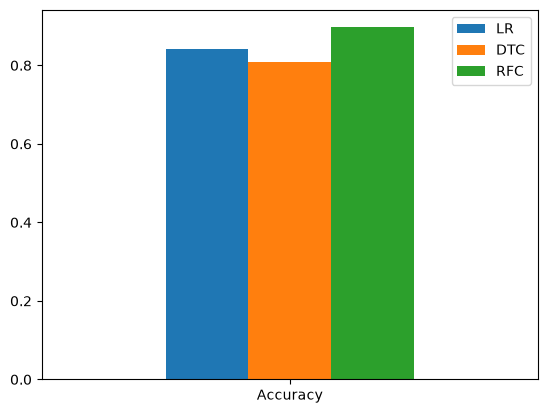

In [48]:
model_score={
    "LR":0.84239130434782600,
    "DTC":0.8097826086956522,
    "RFC":0.8967391304347826
} 
Model_comp=pd.DataFrame(model_score,index=["Accuracy"]).plot(kind="bar")
plt.xticks(rotation=False);

## 10. Model Selection
> * After comparing the tuned models, Random Forest achieved the highest
test accuracy. Therefore, it was selected as the final model for this project.

## 11. RandomForestClassifier Evaluation

In [49]:
print("Classification_Report:\n",classification_report(y_test,Rgs_predy))
print("\nConfusion Matrix:\n",confusion_matrix(y_test,Rgs_predy))

Classification_Report:
               precision    recall  f1-score   support

           0       0.85      0.92      0.88        77
           1       0.94      0.88      0.91       107

    accuracy                           0.90       184
   macro avg       0.89      0.90      0.90       184
weighted avg       0.90      0.90      0.90       184


Confusion Matrix:
 [[71  6]
 [13 94]]


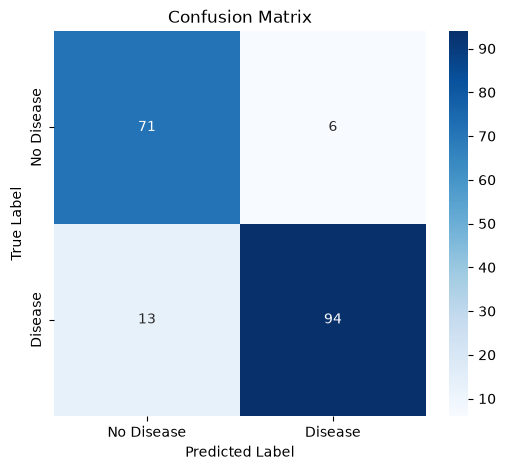

In [50]:
cm = confusion_matrix(y_test, Rgs_predy)

plt.figure(figsize=(6, 5))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["No Disease", "Disease"],
    yticklabels=["No Disease", "Disease"]
)

plt.title("Confusion Matrix")
plt.xlabel("Predicted Label")
plt.ylabel("True Label")

plt.show();

In [51]:
y_prob = Rgs_model.predict_proba(X_test)[:, 1]

ROC_AUC:  0.9439252336448598


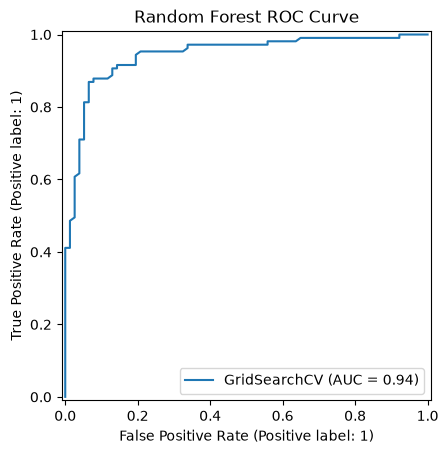

In [52]:
roc_auc=roc_auc_score(y_test,y_prob)
print("ROC_AUC: ",roc_auc)
RocCurveDisplay.from_estimator(Rgs_model,
                               X_test,
                               y_test)
plt.title("Random Forest ROC Curve")
plt.show()

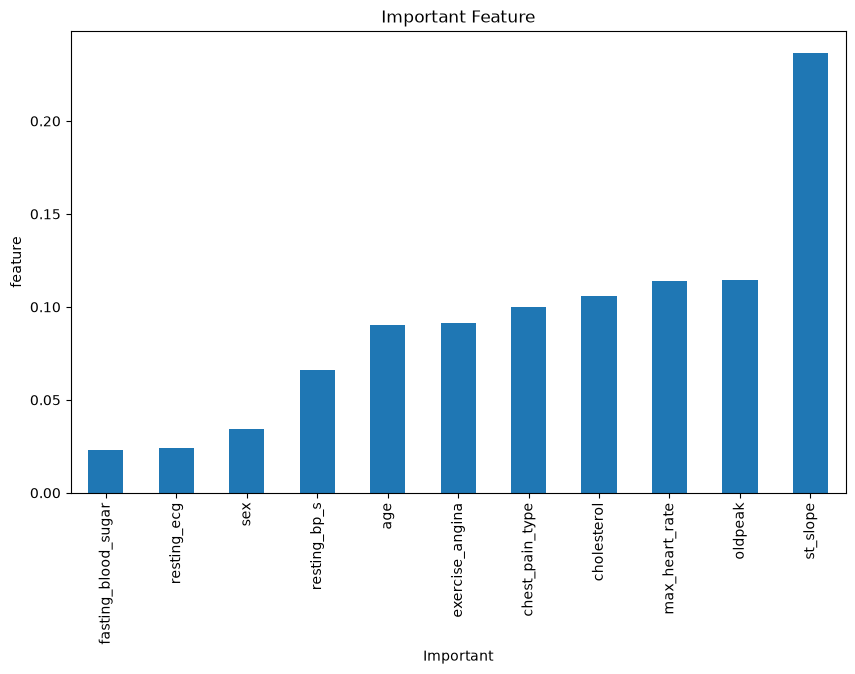

In [53]:
feature_importance = pd.Series(
    Rgs_model.best_estimator_.feature_importances_,
    index=X.columns
).sort_values(ascending=False)


plt.figure(figsize=(10,6))
feature_importance.sort_values().plot(kind="bar")
plt.title("Important Feature")
plt.xlabel("Important")
plt.ylabel("feature")
plt.show();

## 11. Save Final Model

In [54]:
import joblib

# Save the best Random Forest model
joblib.dump(
    Rgs_model.best_estimator_,
    "heart_disease_prediction_model.pkl"
)


['heart_disease_prediction_model.pkl']

In [55]:
# Load the saved model
loaded_model = joblib.load("heart_disease_prediction_model.pkl")

# Make predictions
y_pred = loaded_model.predict(X_test)

print("Loaded model accuracy:",
      accuracy_score(y_test, y_pred))

Loaded model accuracy: 0.8967391304347826


# 12. Conclusion

In this project, Logistic Regression, Decision Tree, and Random Forest
models were trained to predict heart disease.

The models were evaluated using accuracy, precision, recall, F1-score,
confusion matrix, and ROC-AUC.

GridSearchCV was used to improve the model performance.

Random Forest achieved the best overall performance and was selected
as the final model.